#AI/ML-Based Predictive Maintenance and Remaining Useful Life Estimation for Railway Rolling-Stock Subsystems-PVSNMurty
Capstone Project

**QM640: Data Analytics Capstone | Walsh College**  
**Prepared By:** Ponnada VenkataSatyaNarayanaMurty

## Notebook purpose
This notebook provides a runnable analytical framework aligned with the uploaded capstone synopsis:
- **RQ1:** Correlation, anomaly detection and Subsystem Health Index (SHI)
- **RQ2:** Failure classification and classification metrics
- **RQ3:** Remaining Useful Life (RUL) regression
- **RQ4:** Compare predictive-model performance
- **RQ5:** Maintenance-priority illustration

> **Data note:** No operational dataset was attached with the synopsis. To make the notebook executable end-to-end, the notebook creates a **synthetic demonstration dataset**. The resulting scores and predictions are illustrative only; they are not evidence of real railway fleet performance. Replace the synthetic data with approved, real sensor/TCMS/maintenance records before making research claims.

## 1. Research questions and analytical plan

| Research question | Methods | Main outputs |
|---|---|---|
| RQ1 | Pearson/Spearman correlation, Isolation Forest, weighted health index | Correlations, anomaly score, SHI |
| RQ2 | Logistic Regression, Random Forest, XGBoost if installed; confusion matrix and metrics | Accuracy, precision, recall, F1, specificity, FPR, FNR, ROC-AUC, MCC |
| RQ3 | Regression models for RUL | MAE, RMSE, R² |
| RQ4 | Compare models using the same held-out test set | Classification and RUL comparison tables |
| RQ5 | Rule-based example combining health index, predicted failure risk and RUL | Maintenance-priority demonstration |

The synopsis specifies a final minimum analytical sample size of **238 observations/windows**. This notebook generates more than that for demonstration, but this does not replace a documented power or confidence-interval calculation for the final study.

## 2. Imports and reproducibility

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, matthews_corrcoef,
    mean_absolute_error, mean_squared_error, r2_score,
    classification_report
)
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, IsolationForest, ExtraTreesRegressor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported. Random state:", RANDOM_STATE)

Libraries imported. Random state: 42


## 3. Create a synthetic railway subsystem dataset

Features are inspired by the synopsis examples: temperature, current, voltage, vibration, pressure, operating hours, mileage and TCMS fault count. The synthetic failure label and RUL are generated from these variables solely to demonstrate the workflow.

In [2]:
N = 1200  # demonstration rows; replace with approved real data for the study

temperature = np.clip(np.random.normal(68, 10, N), 35, 110)
current = np.clip(np.random.normal(18, 4, N), 4, 35)
voltage = np.clip(np.random.normal(415, 18, N), 340, 460)
vibration = np.clip(np.random.lognormal(mean=0.3, sigma=0.55, size=N), 0.1, 8)
pressure = np.clip(np.random.normal(7.5, 1.2, N), 2, 12)
operating_hours = np.random.uniform(100, 15000, N)
mileage_km = operating_hours * np.random.uniform(15, 45, N)
tcms_fault_count = np.random.poisson(1.2, N)

# A latent degradation score is used only to simulate plausible labels.
temp_deg = np.clip((temperature - 45) / 55, 0, 1)
vib_deg = np.clip(vibration / 6, 0, 1)
current_deg = np.clip((current - 5) / 30, 0, 1)
pressure_deg = np.clip(np.abs(pressure - 8) / 6, 0, 1)
fault_deg = np.clip(tcms_fault_count / 8, 0, 1)

degradation = (
    0.20 * temp_deg + 0.30 * vib_deg + 0.15 * current_deg +
    0.20 * pressure_deg + 0.15 * fault_deg
)
failure_probability = 1 / (1 + np.exp(-12 * (degradation - 0.48)))
failure_within_window = np.random.binomial(1, failure_probability)

# Synthetic RUL in operating hours; bounded at zero.
rul_hours = np.clip(
    5000 * (1 - degradation) + np.random.normal(0, 250, N),
    0, None
)

df = pd.DataFrame({
    "temperature_C": temperature,
    "current_A": current,
    "voltage_V": voltage,
    "vibration": vibration,
    "pressure_bar": pressure,
    "operating_hours": operating_hours,
    "mileage_km": mileage_km,
    "tcms_fault_count": tcms_fault_count,
    "degradation_score": degradation,
    "failure_within_window": failure_within_window,
    "rul_hours": rul_hours
})

print("Dataset shape:", df.shape)
display(df.head())
print("\nFailure-label distribution:")
display(df["failure_within_window"].value_counts().rename(index={0:"No failure label", 1:"Failure label"}).to_frame("count"))

Dataset shape: (1200, 11)


,temperature_C,current_A,voltage_V,vibration,pressure_bar,operating_hours,mileage_km,tcms_fault_count,degradation_score,failure_within_window,rul_hours
0,72.967142,18.500898,402.008724,0.857989,8.108424,5113.110242,82910.489643,5,0.309467,0,3190.086924
1,66.617357,16.282378,418.182776,0.908909,7.431126,3247.003053,60677.835343,1,0.218178,0,3634.784953
2,74.476885,18.489190,405.159758,4.167835,5.825462,4766.412555,100533.735045,0,0.455511,1,2808.132413
3,83.230299,20.173192,410.110208,1.350366,6.650507,2764.731921,74809.658309,0,0.327387,0,3510.401199
4,65.658466,18.195440,445.122138,2.075437,7.184704,13538.550007,546583.029948,0,0.272047,0,3906.039421



Failure-label distribution:


,count
failure_within_window,
No failure label,1066
Failure label,134


## 4. Data quality checks
Check dimensions, missing values, duplicate rows and summary statistics before analysis. With real data, also check timestamp alignment, sensor units, sensor calibration, train/component IDs, maintenance events and leakage between train/test sets.

In [3]:
print("Missing values per column:")
display(df.isna().sum().to_frame("missing_count"))
print("Duplicate rows:", df.duplicated().sum())
display(df.describe().T)

Missing values per column:


,missing_count
temperature_C,0
current_A,0
voltage_V,0
vibration,0
pressure_bar,0
operating_hours,0
mileage_km,0
tcms_fault_count,0
degradation_score,0
failure_within_window,0


Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
temperature_C,1200.0,68.383822,9.883954,35.587327,61.749954,68.483033,74.760141,106.527315
current_A,1200.0,18.098607,3.934987,5.921951,15.432021,18.049251,20.690582,30.772430
voltage_V,1200.0,415.255947,18.283592,361.159553,402.272634,415.306180,427.469891,460.000000
vibration,1200.0,1.507024,0.855128,0.235231,0.913306,1.333412,1.869922,8.000000
pressure_bar,1200.0,7.457913,1.210852,4.020583,6.667569,7.456248,8.259999,11.235492
operating_hours,1200.0,7281.374847,4234.427462,103.619723,3610.841547,7023.078135,10815.068398,14950.580841
mileage_km,1200.0,216557.894072,143188.183317,1600.078892,100238.800204,191688.458983,314480.025916,640333.947251
tcms_fault_count,1200.0,1.210833,1.110891,0.000000,0.000000,1.000000,2.000000,7.000000
degradation_score,1200.0,0.283877,0.067550,0.110857,0.236705,0.280899,0.326621,0.556603
failure_within_window,1200.0,0.111667,0.315087,0.000000,0.000000,0.000000,0.000000,1.000000


## 5. RQ1 — Correlation analysis

Pearson correlation measures linear association; Spearman correlation measures monotonic rank association. Correlation does not establish causation.

Pearson correlations with degradation score:


,degradation_score
degradation_score,1.000000
vibration,0.608384
temperature_C,0.540023
current_A,0.312565
tcms_fault_count,0.291136
mileage_km,0.021250
operating_hours,0.004278
voltage_V,-0.008643
pressure_bar,-0.159195


Spearman correlations with degradation score:


,degradation_score
degradation_score,1.000000
vibration,0.575440
temperature_C,0.529896
current_A,0.317235
tcms_fault_count,0.282603
mileage_km,0.017623
operating_hours,0.003100
voltage_V,-0.023555
pressure_bar,-0.199890


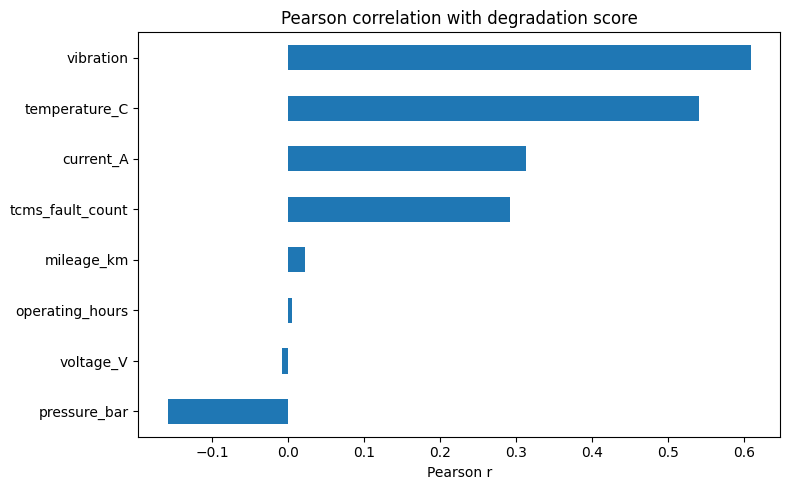

In [4]:
condition_cols = [
    "temperature_C", "current_A", "voltage_V", "vibration",
    "pressure_bar", "operating_hours", "mileage_km", "tcms_fault_count"
]

pearson_corr = df[condition_cols + ["degradation_score"]].corr(method="pearson")
spearman_corr = df[condition_cols + ["degradation_score"]].corr(method="spearman")

print("Pearson correlations with degradation score:")
display(pearson_corr[["degradation_score"]].sort_values("degradation_score", ascending=False))
print("Spearman correlations with degradation score:")
display(spearman_corr[["degradation_score"]].sort_values("degradation_score", ascending=False))

pearson_corr["degradation_score"].drop("degradation_score").sort_values().plot(
    kind="barh", title="Pearson correlation with degradation score", figsize=(8, 5)
)
plt.xlabel("Pearson r")
plt.tight_layout()
plt.show()

## 6. RQ1 — Anomaly detection

Isolation Forest flags unusual multivariate observations. An anomaly is not automatically a confirmed failure; validate flagged events against maintenance records and engineering review.

In [5]:
iso = IsolationForest(contamination=0.05, random_state=RANDOM_STATE)
df["anomaly_flag"] = iso.fit_predict(df[condition_cols])
df["is_anomaly"] = (df["anomaly_flag"] == -1)

print("Anomalies flagged:", int(df["is_anomaly"].sum()), "of", len(df))
display(df.loc[df["is_anomaly"], condition_cols + ["degradation_score", "failure_within_window"]].head(10))

Anomalies flagged: 60 of 1200


,temperature_C,current_A,voltage_V,vibration,pressure_bar,operating_hours,mileage_km,tcms_fault_count,degradation_score,failure_within_window
10,63.365823,13.024547,429.737998,1.375359,8.407786,14571.176687,470818.036306,4,0.264268,0
71,83.380366,20.436552,457.549705,2.180978,9.132139,896.175576,19204.148355,0,0.363535,0
86,77.154021,10.655179,408.031648,5.295484,6.573874,14046.313267,214782.325728,0,0.457511,1
116,67.652882,13.739545,416.546074,8.000000,8.775189,13555.454731,267381.567456,1,0.470661,1
117,56.313220,16.779101,375.052593,4.803544,7.049240,2181.836448,71629.585898,0,0.371904,0
121,58.906125,20.118771,460.000000,3.444384,7.866292,8181.559747,363274.001997,3,0.359088,0
167,86.967930,14.266928,426.720452,2.764692,8.843094,483.561905,15294.907328,5,0.459033,0
174,70.766908,23.884681,460.000000,0.509621,5.733556,13200.144630,450433.305235,2,0.326650,0
176,68.130019,15.323709,441.355190,0.493057,9.154164,14176.776195,217495.706190,5,0.292603,0
179,95.201692,25.304039,446.655169,1.287448,4.835495,13870.854679,600306.889450,1,0.472678,1


## 7. RQ1 — Subsystem Health Index (SHI)

The synopsis proposes **HI = 100 × (1 − D)**, where D is normalized degradation. Example weights are temperature 0.20, vibration 0.30, current 0.15, pressure 0.20 and TCMS faults 0.15. These weights and bands are project-defined and should be validated with domain experts and actual failure/maintenance history.

,health_index,health_category,maintenance_priority_from_HI
0,69.053324,Normal / Warning,Medium
1,78.182160,Normal / Warning,Medium
2,54.448903,Degraded,High
3,67.261338,Normal / Warning,Medium
4,72.795274,Normal / Warning,Medium
5,73.487742,Normal / Warning,Medium
6,71.779748,Normal / Warning,Medium
7,70.491039,Normal / Warning,Medium
8,80.518308,Healthy,Low
9,69.073557,Normal / Warning,Medium


,count
health_category,
Normal / Warning,1012
Healthy,128
Degraded,60


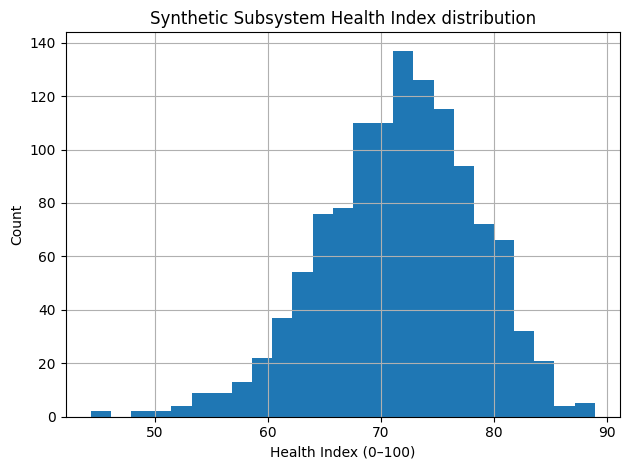

In [6]:
df["D_temperature"] = temp_deg
df["D_vibration"] = vib_deg
df["D_current"] = current_deg
df["D_pressure"] = pressure_deg
df["D_tcms_faults"] = fault_deg

weights = {
    "D_temperature": 0.20,
    "D_vibration": 0.30,
    "D_current": 0.15,
    "D_pressure": 0.20,
    "D_tcms_faults": 0.15
}
df["overall_degradation"] = sum(df[col] * weight for col, weight in weights.items())
df["health_index"] = 100 * (1 - df["overall_degradation"])

def health_category(hi):
    if hi >= 80:
        return "Healthy"
    elif hi >= 60:
        return "Normal / Warning"
    elif hi >= 40:
        return "Degraded"
    return "Critical"

def maintenance_priority(hi):
    if hi >= 80:
        return "Low"
    elif hi >= 60:
        return "Medium"
    elif hi >= 40:
        return "High"
    return "Very High"

df["health_category"] = df["health_index"].apply(health_category)
df["maintenance_priority_from_HI"] = df["health_index"].apply(maintenance_priority)

display(df[["health_index", "health_category", "maintenance_priority_from_HI"]].head(10))
display(df["health_category"].value_counts().to_frame("count"))

df["health_index"].hist(bins=25)
plt.title("Synthetic Subsystem Health Index distribution")
plt.xlabel("Health Index (0–100)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## 8. RQ2 — Failure classification

The target is `failure_within_window`. Features exclude the synthetic target-generation fields (`degradation_score`, RUL and health index) to avoid direct target leakage. For a real dataset, select features available at the prediction time and split by time or component where appropriate.

In [7]:
X = df[condition_cols].copy()
y = df["failure_within_window"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

classifiers = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300, min_samples_leaf=2, class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ])
}

classification_results = []
fitted_classifiers = {}

for name, model in classifiers.items():
    model.fit(X_train, y_train)
    fitted_classifiers[name] = model
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) else np.nan
    fpr = fp / (fp + tn) if (fp + tn) else np.nan
    fnr = fn / (fn + tp) if (fn + tp) else np.nan
    classification_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall / Sensitivity": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "Specificity": specificity,
        "FPR": fpr,
        "FNR": fnr,
        "ROC-AUC": roc_auc_score(y_test, prob) if len(np.unique(y_test)) > 1 else np.nan,
        "MCC": matthews_corrcoef(y_test, pred),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    })

classification_results_df = pd.DataFrame(classification_results).set_index("Model")
display(classification_results_df.style.format("{:.3f}", subset=[
    "Accuracy", "Precision", "Recall / Sensitivity", "F1-score",
    "Specificity", "FPR", "FNR", "ROC-AUC", "MCC"
]))

,Accuracy,Precision,Recall / Sensitivity,F1-score,Specificity,FPR,FNR,ROC-AUC,MCC,TN,FP,FN,TP
Model,,,,,,,,,,,,,
Logistic Regression,0.687,0.210,0.667,0.319,0.689,0.311,0.333,0.732,0.233,184,83,11,22
Random Forest,0.890,0.000,0.000,0.000,1.000,0.000,1.000,0.652,0.000,267,0,33,0


### Confusion matrix and report for the selected classifier

For railway predictive maintenance, do not select a model on accuracy alone. Review recall/FNR, precision, false alarms, calibration and operational consequences. The best threshold depends on the maintenance policy and safety analysis.

Selected by held-out F1-score: Logistic Regression
              precision    recall  f1-score   support

           0       0.94      0.69      0.80       267
           1       0.21      0.67      0.32        33

    accuracy                           0.69       300
   macro avg       0.58      0.68      0.56       300
weighted avg       0.86      0.69      0.74       300



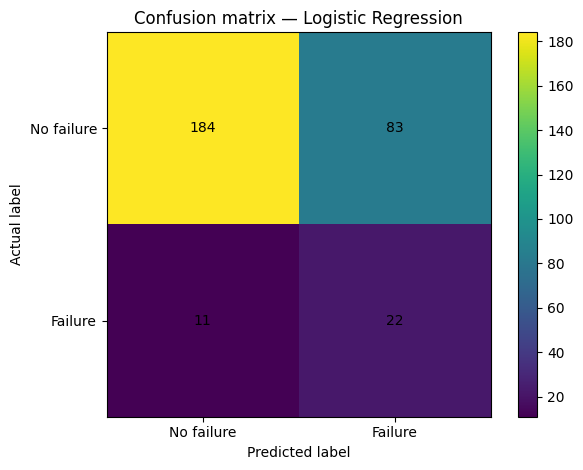

In [8]:
selected_name = classification_results_df["F1-score"].idxmax()
selected_model = fitted_classifiers[selected_name]
selected_pred = selected_model.predict(X_test)
selected_prob = selected_model.predict_proba(X_test)[:, 1]

print("Selected by held-out F1-score:", selected_name)
print(classification_report(y_test, selected_pred, zero_division=0))
cm = confusion_matrix(y_test, selected_pred, labels=[0, 1])
plt.imshow(cm)
plt.title(f"Confusion matrix — {selected_name}")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.xticks([0, 1], ["No failure", "Failure"])
plt.yticks([0, 1], ["No failure", "Failure"])
for (i, j), value in np.ndenumerate(cm):
    plt.text(j, i, str(value), ha="center", va="center")
plt.colorbar()
plt.tight_layout()
plt.show()

## 9. RQ3 — Remaining Useful Life (RUL) regression

RUL is a continuous target, so use regression metrics rather than classification accuracy. This demonstration predicts synthetic RUL in operating hours. For real RUL labels, document the failure/end-of-life definition, censoring and maintenance/replacement resets.

In [9]:
# Exclude RUL itself and derived degradation/health features from predictors.
X_rul = df[condition_cols].copy()
y_rul = df["rul_hours"].copy()

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_rul, y_rul, test_size=0.25, random_state=RANDOM_STATE
)

rul_models = {
    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Random Forest Regressor": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE
        ))
    ]),
    "Extra Trees Regressor": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", ExtraTreesRegressor(
            n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE
        ))
    ])
}

rul_results = []
fitted_rul_models = {}
for name, model in rul_models.items():
    model.fit(Xr_train, yr_train)
    fitted_rul_models[name] = model
    pred_rul = model.predict(Xr_test)
    rul_results.append({
        "Model": name,
        "MAE_hours": mean_absolute_error(yr_test, pred_rul),
        "RMSE_hours": mean_squared_error(yr_test, pred_rul) ** 0.5,
        "R2": r2_score(yr_test, pred_rul)
    })

rul_results_df = pd.DataFrame(rul_results).set_index("Model").sort_values("MAE_hours")
display(rul_results_df.style.format("{:.3f}"))

,MAE_hours,RMSE_hours,R2
Model,,,
Linear Regression,221.071,281.885,0.572
Extra Trees Regressor,224.830,281.946,0.571
Random Forest Regressor,227.817,286.941,0.556


### Actual vs predicted RUL plot

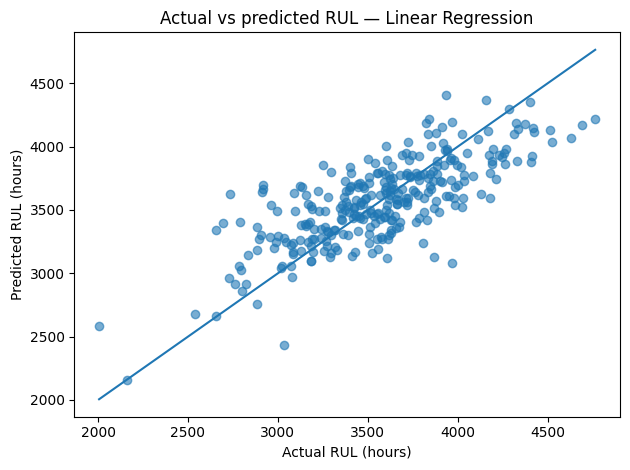

Best model by MAE: Linear Regression
MAE (hours): 221.07
RMSE (hours): 281.89
R²: 0.572


In [10]:
best_rul_name = rul_results_df["MAE_hours"].idxmin()
best_rul_model = fitted_rul_models[best_rul_name]
best_rul_pred = best_rul_model.predict(Xr_test)

plt.scatter(yr_test, best_rul_pred, alpha=0.6)
limits = [
    min(float(yr_test.min()), float(best_rul_pred.min())),
    max(float(yr_test.max()), float(best_rul_pred.max()))
]
plt.plot(limits, limits)
plt.xlabel("Actual RUL (hours)")
plt.ylabel("Predicted RUL (hours)")
plt.title(f"Actual vs predicted RUL — {best_rul_name}")
plt.tight_layout()
plt.show()

print("Best model by MAE:", best_rul_name)
print("MAE (hours):", round(mean_absolute_error(yr_test, best_rul_pred), 2))
print("RMSE (hours):", round(mean_squared_error(yr_test, best_rul_pred) ** 0.5, 2))
print("R²:", round(r2_score(yr_test, best_rul_pred), 3))

## 10. RQ4 — Model comparison

Use a consistent test strategy and compare models using metrics suited to the task. For classification, emphasize recall, F1, ROC-AUC, MCC and FNR; for RUL regression, emphasize MAE, RMSE and R². If multiple repeated runs or folds are used, compare fold-level scores; ANOVA/repeated-measures ANOVA assumptions must be checked before reporting significance.

In [11]:
print("Classification model comparison:")
display(classification_results_df.sort_values("F1-score", ascending=False))
print("RUL regression model comparison:")
display(rul_results_df)

Classification model comparison:


,Accuracy,Precision,Recall / Sensitivity,F1-score,Specificity,FPR,FNR,ROC-AUC,MCC,TN,FP,FN,TP
Model,,,,,,,,,,,,,
Logistic Regression,0.686667,0.209524,0.666667,0.318841,0.689139,0.310861,0.333333,0.732153,0.233407,184,83,11,22
Random Forest,0.890000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.651685,0.000000,267,0,33,0


RUL regression model comparison:


,MAE_hours,RMSE_hours,R2
Model,,,
Linear Regression,221.070969,281.885066,0.571673
Extra Trees Regressor,224.830036,281.946480,0.571486
Random Forest Regressor,227.817431,286.940651,0.556171


## 11. RQ5 — Maintenance decision illustration

This is a transparent, rule-based example—not a certified railway maintenance rule. Actual thresholds must be agreed with engineering, RAMS/safety and maintenance teams and validated against historical records.

In [12]:
# Create example predictions for the first 10 test rows.
sample_idx = X_test.index[:10]
sample = df.loc[sample_idx, [
    "health_index", "health_category", "maintenance_priority_from_HI", "rul_hours"
]].copy()
sample["predicted_failure_probability"] = selected_model.predict_proba(X.loc[sample_idx])[:, 1]
sample["predicted_RUL_hours"] = best_rul_model.predict(X_rul.loc[sample_idx])

def recommended_action(row):
    if row["health_index"] < 40 or row["predicted_RUL_hours"] < 250 or row["predicted_failure_probability"] >= 0.75:
        return "Very high: engineering review / urgent inspection"
    elif row["health_index"] < 60 or row["predicted_RUL_hours"] < 750 or row["predicted_failure_probability"] >= 0.50:
        return "High: prioritize inspection and maintenance planning"
    elif row["health_index"] < 80 or row["predicted_RUL_hours"] < 1500:
        return "Medium: monitor condition and schedule review"
    return "Low: continue routine monitoring"

sample["illustrative_maintenance_action"] = sample.apply(recommended_action, axis=1)
display(sample.round(3))

,health_index,health_category,maintenance_priority_from_HI,rul_hours,predicted_failure_probability,predicted_RUL_hours,illustrative_maintenance_action
916,77.883,Normal / Warning,Medium,3607.993,0.295,3762.100,Medium: monitor condition and schedule review
1187,77.830,Normal / Warning,Medium,3517.674,0.362,3802.733,Medium: monitor condition and schedule review
1143,69.409,Normal / Warning,Medium,3466.496,0.531,3580.900,High: prioritize inspection and maintenance pl...
301,79.777,Normal / Warning,Medium,3975.622,0.271,3881.619,Medium: monitor condition and schedule review
726,80.583,Healthy,Low,4373.042,0.198,4083.609,Low: continue routine monitoring
920,62.218,Normal / Warning,Medium,3020.382,0.587,3055.404,High: prioritize inspection and maintenance pl...
982,82.124,Healthy,Low,3825.379,0.126,3983.828,Low: continue routine monitoring
533,71.580,Normal / Warning,Medium,3596.368,0.300,3654.202,Medium: monitor condition and schedule review
993,85.315,Healthy,Low,3937.432,0.112,4152.055,Low: continue routine monitoring
975,73.100,Normal / Warning,Medium,3870.969,0.231,3754.440,Medium: monitor condition and schedule review


## 12. Export results

The following cell exports the synthetic demonstration dataset and metric tables. Do not label synthetic data as actual fleet data in a report or submission.

In [12]:
output_dir = "."
df.to_csv(f"{output_dir}/synthetic_railway_predictive_maintenance_data.csv", index=False)
classification_results_df.to_csv(f"{output_dir}/classification_model_metrics.csv")
rul_results_df.to_csv(f"{output_dir}/rul_model_metrics.csv")
print("Exported synthetic dataset and model-metric tables to the notebook's current working directory.")

Exported synthetic dataset and model-metric tables to the notebook's current working directory.


## 13. Research reporting checklist

Before using results in the final capstone report:
1. Replace synthetic data with traceable, approved railway component records.
2. Provide a data dictionary, units, source, collection frequency, component ID and timestamp definitions.
3. Define failure labels and the prediction horizon before model training.
4. Define how RUL is calculated, including the end-of-life threshold and handling of censored components.
5. Use time-based or component-grouped train/test splits where appropriate to prevent leakage.
6. Report class balance, confusion matrix, precision, recall, F1, specificity, FPR, FNR, ROC-AUC and MCC.
7. Report RUL MAE/RMSE/R² and, where feasible, prediction intervals.
8. Validate SHI weights and health-category boundaries with engineering evidence.
9. Document software versions, preprocessing, hyperparameters and random seeds.
10. Do not interpret synthetic demonstration metrics as validated performance on real railway equipment.

### Synopsis alignment
This notebook follows the synopsis topics: condition-variable relationships, anomaly/degradation, health index, failure classification, RUL regression, model comparison and maintenance-priority insights. Some advanced methods named in the synopsis (for example XGBoost, SVM, LSTM/GRU, survival analysis and formal ANOVA) can be added after the real dataset format and sample structure are known.